# Token attribution visualization

**Business context:** Stakeholders rarely accept raw attribution vectors. Coloured words and sorted bars make Shapley and Banzhaf results legible in compliance reviews and product postmortems, and the HTML export drops straight into a report.

**Goal:** Explain a short refund request and show every built-in way to display the result: `render_attribution` with the `token_text` and `token_bar` renderers, `display_attribution_html` and `render_attribution_html`, the renderer classes used directly, and a renderer resolved from the run's own registry with the estimand in the title.

**Prerequisites:** `mllm-shap[viz]` (matplotlib, seaborn), Python 3.12. A rule-based stand-in plays the model (see `explain_pipeline.ipynb`), so no model is downloaded.

**Expected output:** Values with both signs that add up to `grand_value - base_value`, two figures, an inline HTML view, and a Banzhaf bar chart labelled as such.

In [1]:
import re

import matplotlib.pyplot as plt

from mllm_shap import (
    ConversationSnapshot,
    ExplainConfig,
    ExplainRunner,
    GenerationRecord,
    Message,
    Role,
    TokenBarRenderer,
    TokenTextRenderer,
    Turn,
    display_attribution_html,
    render_attribution,
    render_attribution_html,
)
from mllm_shap.domain.config import GenerationConfig
from mllm_shap.value.generation_records import generation_record_from_text

## Explain a refund request

**Business:** A late request is refused even with a receipt; reviewers want to see which words pushed the answer to the refusal.

**Technical:** The stand-in answers "refund denied" when `late` reaches it, "refund approved" (plus "receipt checked" when `receipt` is present) otherwise, and asks for clarification without `refund`. `tfidf_cosine` scores each coalition's answer against the answer for the full prompt, so a word earns credit when it moves the answer toward the refusal and loses credit when it moves the answer away from it.

In [2]:
class RefundBot:
    """Rule-based stand-in for a support model."""

    model_id = "refund-bot"

    async def generate(
        self, snapshot: ConversationSnapshot, generation: GenerationConfig
    ) -> GenerationRecord:
        """Refuse late requests; approve the others, checking a receipt."""
        _ = generation
        prompt = " ".join(message.text for message in snapshot.messages())
        words = set(re.findall(r"[a-z]+", prompt.lower()))
        if "refund" not in words:
            reply = "please clarify"
        elif "late" in words:
            reply = "refund denied"
        else:
            reply = "refund approved" + (
                " receipt checked" if "receipt" in words else ""
            )
        return generation_record_from_text(reply)

In [3]:
snapshot = ConversationSnapshot.from_turns((
    Turn(
        messages=(
            Message(role=Role.USER, text="Refund request with receipt, sent late."),
        )
    ),
))


def explain_config(estimand: str) -> ExplainConfig:
    """Exact enumeration with the given estimand, no archive."""
    return ExplainConfig.model_validate({
        "backend": {"kind": "mock", "model_id": "refund-bot"},
        "explanation": {
            "estimator": "exact",
            "estimand": estimand,
            "value_fn": "tfidf_cosine",
            "absence_policy": "delete",
            "archive": {"path": ""},
        },
    })


runner = ExplainRunner(explain_config("shapley"), backend=RefundBot())
output = await runner.explain(snapshot)
result = output.result
for span, value in zip(output.player_set.spans, result.values, strict=True):
    print(f"{span.text:>9} {value:+.4f}")
print("base_value:", result.base_value, " grand_value:", result.grand_value)
print("sum of values:", round(sum(result.values), 6))

   Refund +0.6444
  request +0.0000
     with +0.0000
 receipt, -0.0246
     sent +0.0000
    late. +0.3802
base_value: 0.0  grand_value: 1.0
sum of values: 1.0


`Refund` and `late` carry the refusal and get positive values. `receipt,` gets a small negative value: in coalitions without `late` it adds "receipt checked" to an approval, which moves the answer further from the refusal. The other words never change the answer and get 0. The values add up to `grand_value - base_value`.

## Coloured words

**Business:** The inline view keeps the words in reading order, which suits non-technical readers.

**Technical:** `render_attribution(output, snapshot, player_set, renderer="token_text")` returns a matplotlib figure; pass the run's `output.player_set` so labels match the players. In Jupyter, `display_attribution_html` shows the same view as HTML without matplotlib. Both use the SHAP palette: red for positive, blue for negative, white-centred highlights whose intensity follows the value.

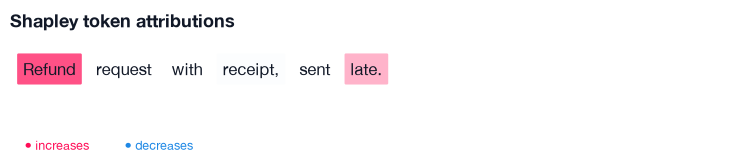

In [4]:
render_attribution(output, snapshot, output.player_set, renderer="token_text")
plt.show()
display_attribution_html(output, snapshot, output.player_set, title="Refund request")

## Bars sorted by impact

**Technical:** `token_bar` sorts the players by absolute value and annotates each bar with its signed value. `render_attribution_html` returns the HTML fragment as a string, for reports and emails.

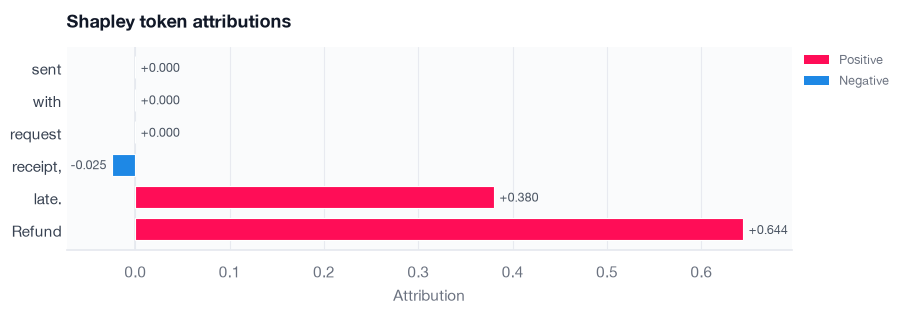

HTML fragment: 1531 characters; coloured spans: 6


In [5]:
render_attribution(output, snapshot, output.player_set, renderer="token_bar")
plt.show()
html = render_attribution_html(
    output, snapshot, output.player_set, title="Refund request"
)
print(
    "HTML fragment:",
    len(html),
    "characters; coloured spans:",
    html.count("background-color"),
)

## Renderers directly, and Banzhaf values

**Business:** Charts in a report must say which estimand they show; a Banzhaf chart labelled "Shapley" misleads.

**Technical:** `TokenTextRenderer` and `TokenBarRenderer` are the plugin classes behind the renderer names: `render(labels, values, estimand=..., title=...)` draws any labelled vector, and `TokenTextRenderer.to_html` returns the HTML fragment. `render_attribution(..., registry=runner.registry)` resolves renderers from the runner's registry, which matters when you registered your own renderer there. Without `title=`, the bar chart title names the estimand of the run.

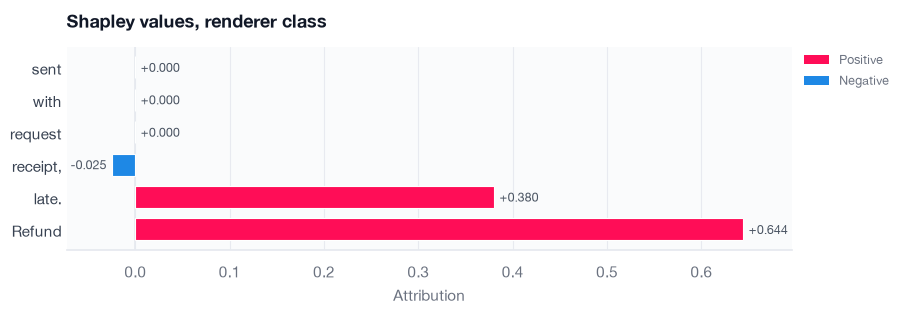

to_html matches: True
Banzhaf: [0.6321, 0.0, 0.0, -0.0369, 0.0, 0.3679]
Banzhaf sum: 0.9631 (Banzhaf values need not add up)


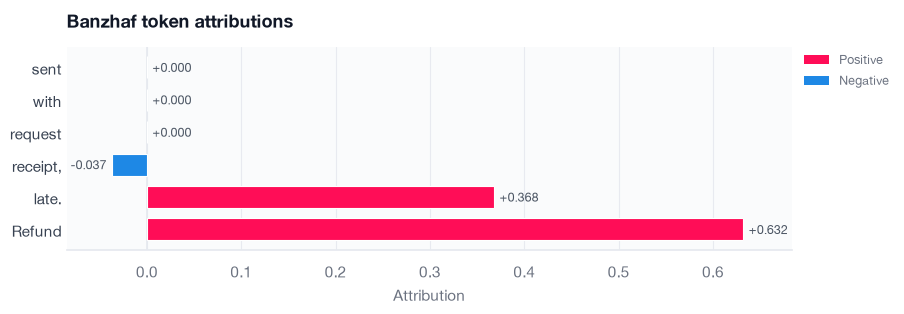

In [6]:
labels = [span.text for span in output.player_set.spans]
TokenBarRenderer().render(
    labels,
    result.values,
    estimand=result.estimand,
    title="Shapley values, renderer class",
)
plt.show()
print(
    "to_html matches:",
    TokenTextRenderer().to_html(labels, result.values, estimand=result.estimand)
    == render_attribution_html(output, snapshot, output.player_set),
)

banzhaf_runner = ExplainRunner(explain_config("banzhaf"), backend=RefundBot())
banzhaf = await banzhaf_runner.explain(snapshot)
print("Banzhaf:", [round(value, 4) for value in banzhaf.result.values])
print(
    "Banzhaf sum:",
    round(sum(banzhaf.result.values), 4),
    "(Banzhaf values need not add up)",
)
render_attribution(
    banzhaf,
    snapshot,
    banzhaf.player_set,
    renderer="token_bar",
    registry=banzhaf_runner.registry,
)
plt.show()